# SE

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from src import config, eda, utils, pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

In [2]:
from src.features_static import _split_types

tr = utils.load_raw("se_train")
y = utils.load_target()
key = utils.find_col(tr, "key", required=True)
_, cats, nums = _split_types(tr.drop(columns=[key]))
print(tr.shape, "| llaves duplicadas:", tr[key].duplicated().sum())
print("nominales:", cats)
print("numericas:", nums)
eda.overview(tr, "se_train")

(358428, 15) | llaves duplicadas: 0
nominales: ['sexo', 'est_cvl', 'sit_lab', 'cod_ocu', 'flg_sin_email', 'lgr_vot', 'prv', 'dto', 'rgn', 'tip_lvledu']
numericas: ['edad', 'ctd_hijos', 'ctd_veh', 'cod_ubi']
se_train: 358,428 filas x 15 columnas


,dtype,nulos_%,unicos,ejemplo
key_value,int64,0.00,358428,0.000000
edad,float64,1.05,80,-0.983651
sexo,int64,0.00,4,1.000000
est_cvl,int64,0.00,6,4.000000
sit_lab,int64,0.00,4,2.000000
cod_ocu,int64,0.00,39,22.000000
ctd_hijos,float64,0.00,12,0.000000
flg_sin_email,int64,0.00,2,1.000000
ctd_veh,float64,0.00,47,0.000000
cod_ubi,float64,1.16,2070,-0.070167


## Nulos y distribuciones

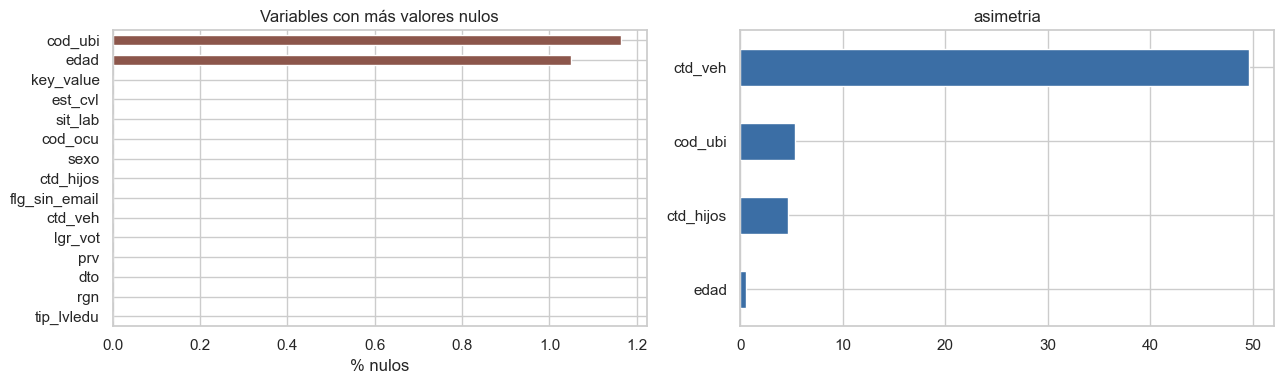

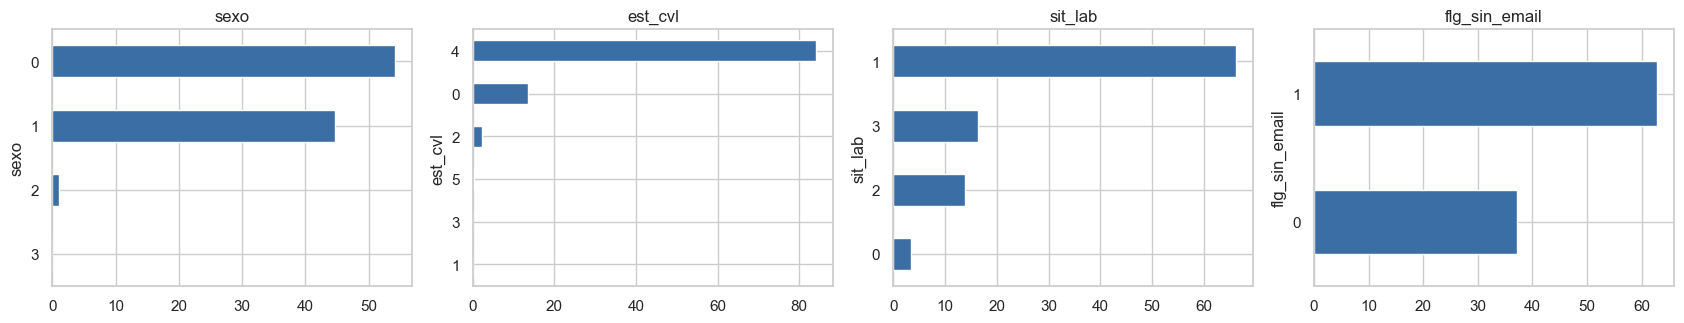

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
eda.missing_plot(tr, ax=axes[0])
tr[nums].skew().sort_values(key=abs, ascending=False).head(12)[::-1].plot.barh(ax=axes[1], color="#3b6ea5")
axes[1].set_title("asimetria")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, c in zip(axes, [c for c in cats if tr[c].nunique() <= 30][:4]):
    tr[c].astype(str).value_counts(normalize=True).head(10)[::-1].mul(100).plot.barh(ax=ax, color="#3b6ea5")
    ax.set_title(c)
plt.tight_layout()
plt.show()

## Construcción de variables

In [4]:
del tr
pipeline.run_static("se")
X, uni = eda.source_univariate("se", y)
print(X.shape)
uni.head(15)

00:10:40 | INFO | se: 4 numéricas, 10 categóricas, 0 fechas
00:10:42 | INFO | se: se eliminan 0 numéricas con |corr| > 0.95
00:10:47 | INFO | SE listo: train (358428, 16) | test (396609, 16)


(358428, 15)


,variable,auc_univariado,iv,nulos_pct,lectura_iv
0,se_sit_lab,NaN,0.165021,0.0,media
1,se_dto,NaN,0.129246,0.0,media
2,se_prv,NaN,0.088884,0.0,débil
3,se_lgr_vot,NaN,0.060076,0.0,débil
4,se_tip_lvledu,NaN,0.047682,0.0,débil
5,se_edad,0.559218,0.046202,1.0,débil
6,se_flg_sin_email,NaN,0.031846,0.0,débil
7,se_cod_ubi,0.528176,0.031032,1.1,débil
8,se_rgn,NaN,0.028194,0.0,débil
9,se_cod_ocu,NaN,0.018962,0.0,inútil


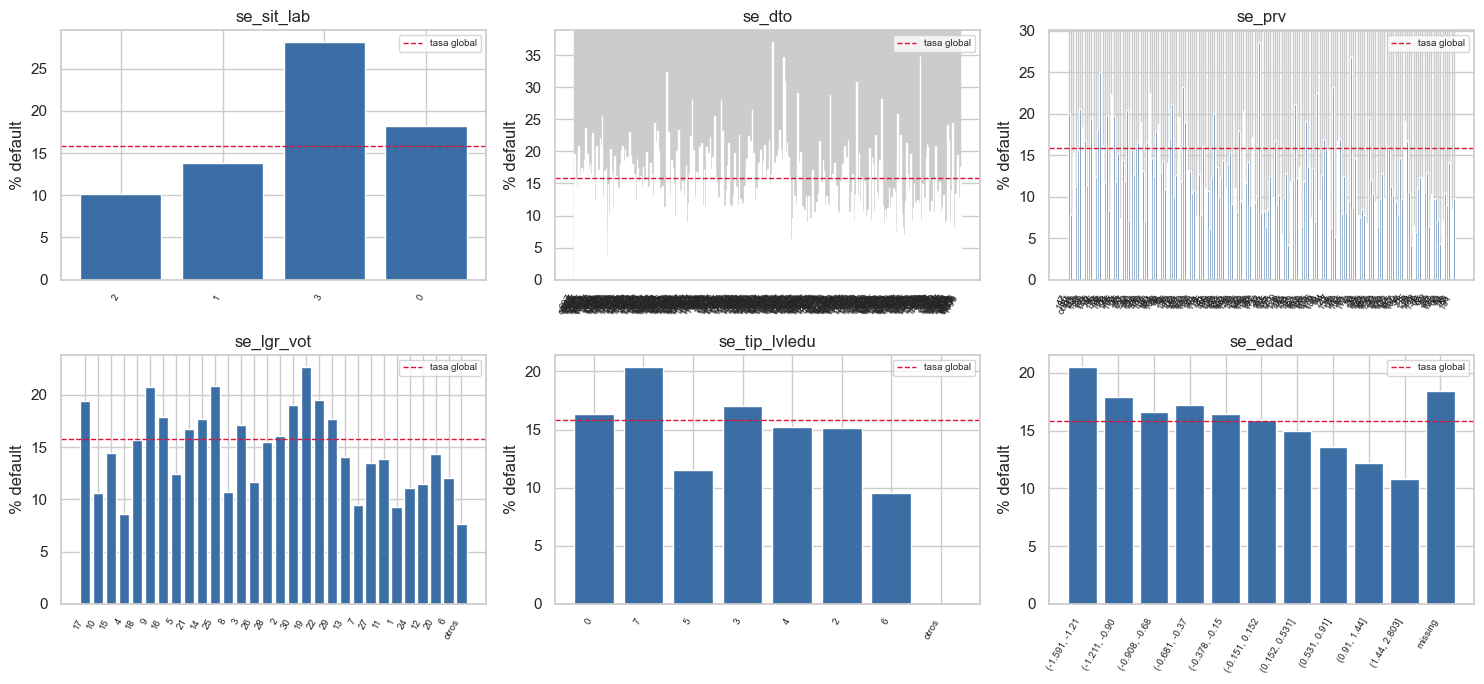

In [5]:
top = uni.variable.head(6).tolist()
idx = X.index.intersection(y.index)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), top):
    eda.default_rate_by_bin(X.loc[idx, c], y.loc[idx], ax=ax)
plt.tight_layout()
plt.show()